In [8]:
%matplotlib inline

In [ ]:
from pathlib import Path
import sys
cwd = Path.cwd().resolve()
repo_root = next(
    (path for path in [cwd, *cwd.parents]
        if (path / "application_mnist" / "data" / "mnist_io.py").exists()
    ),None)
if repo_root is None:
    raise FileNotFoundError("")

sys.path.insert(0, str(repo_root))
print("repo root:", repo_root)

Repository root: C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback


In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from application_mnist.data.mnist_io import load_mnist
from application_mnist.data.features import FeatureSpec
from application_mnist.data.pipeline import BinaryTask, prepare_dataset, save_prepared
from application_mnist.eda.explore import raw_report, prepared_report, compare_grids

root = Path("application_mnist")
raw = load_mnist()
print("Original images:", raw["train_images"].shape, raw["test_images"].shape)
print("Train counts:", np.bincount(raw["train_labels"], minlength=10))
print("Test counts:", np.bincount(raw["test_labels"], minlength=10))

Original images: (60000, 28, 28) (10000, 28, 28)
Train counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Test counts: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


{'train_size': 60000,
 'test_size': 10000,
 'image_shape': [28, 28],
 'dtype': 'uint8',
 'train_digit_counts': [5923,
  6742,
  5958,
  6131,
  5842,
  5421,
  5918,
  6265,
  5851,
  5949],
 'test_digit_counts': [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009],
 'train_mean_pixel_intensity': 33.3184,
 'train_fraction_nonzero_pixels': 0.1912,
 'test_fraction_nonzero_pixels': 0.19276}

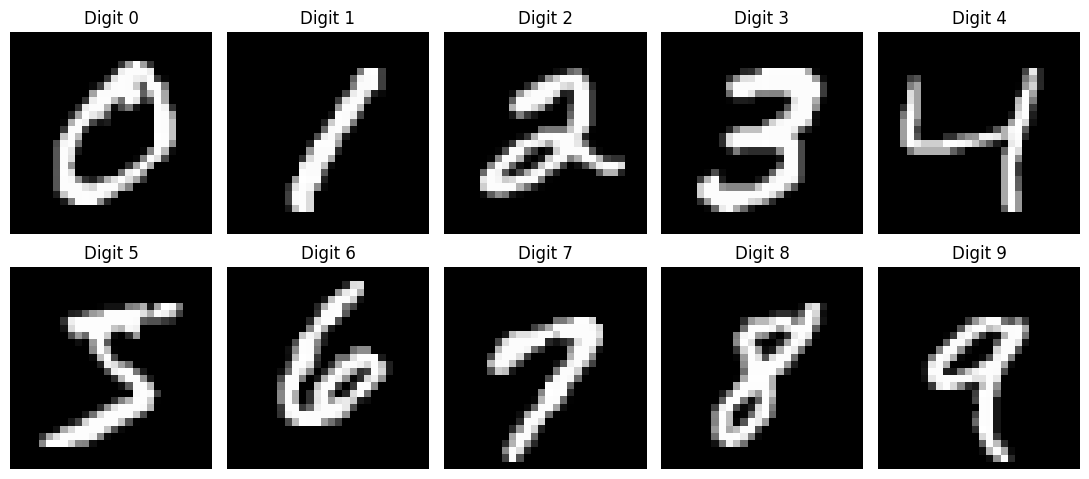

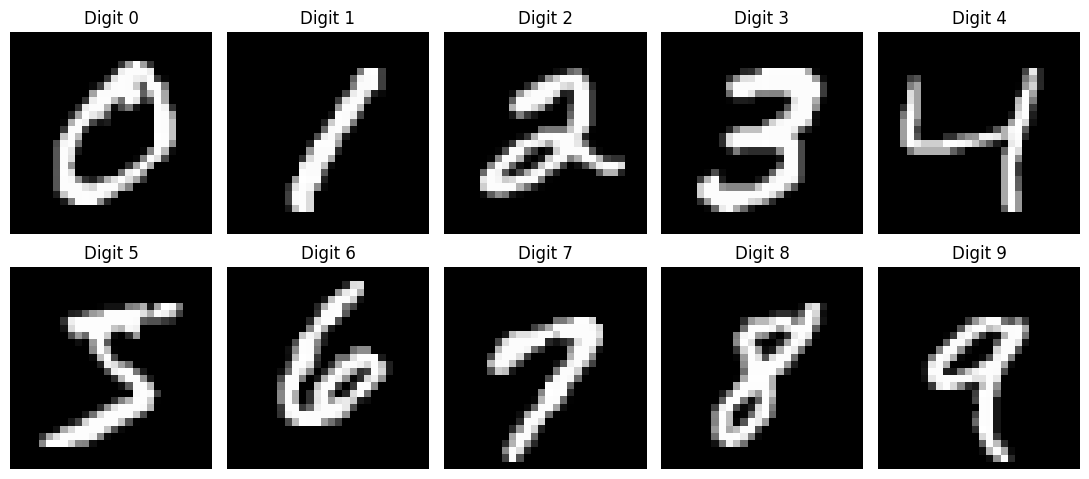

In [11]:
raw_summary = raw_report(raw, root / "eda" / "reports" / "raw")
raw_summary

## TASK

options:
- `BinaryTask(kind="pair", positive_digit=3, negative_digit=8)`
- `BinaryTask(kind="digit", positive_digit=3)`
- `BinaryTask(kind="parity", positive_parity="odd")`
- `BinaryTask(kind="parity", positive_parity="odd", digits=(0,1,2,3))`. 


Default grid 7x7 = 49 

Set `balance=True` for same amount 

In [20]:
task = BinaryTask(kind="parity", positive_parity="odd")

feature_spec = FeatureSpec(grid_size=7, threshold=0.20)
prepared = prepare_dataset(
    raw, task=task, features=feature_spec,
    train_limit=2000, test_limit=400, val_fraction=0.20,
    seed=10, balance=False,
)
output = root / "data" / "processed" / f"{task.name}_g7_t20_seed10.npz"
save_prepared(prepared, output)
print("Saved:", output)
print(prepared["metadata"]["splits"])
print("train features:", prepared["train_features"].shape)

Saved: application_mnist\data\processed\odd_vs_other_parity_g7_t20_seed10.npz
{'train': {'total': 1600, 'positive': 814, 'negative': 786}, 'val': {'total': 400, 'positive': 203, 'negative': 197}, 'test': {'total': 400, 'positive': 203, 'negative': 197}}
train features: (1600, 49)


## EDA

this is to see if reducing the dimentionality causes the vectors of different classes (e.g 3 and 8) to collide.

The report says:

- n_features: number of Boolean variables
- unique_boolean_patterns: number of distinct Boolean vectors
- repeated_examples: number of examples beyond the first occurrence of each vector
- conflicting_label_patterns: number of distinct vectors associated with both labels
- min_in_sample_errors_from_collisions: minimum number of unavoidable mistakes on the training examples
- best_possible_in_sample_accuracy_given_features: upper bound on training accuracy imposed by the representation
- constant_features: variables always 0 or always 1 in training
- mean_active_features: average number of Boolean variables equal to 1 per image

In [22]:
report = prepared_report(prepared, root / "eda" / "reports" / output.stem / "prepared")
for key, value in report.items():
    print(key, ":", value)

n_examples : 1600
n_features : 49
unique_boolean_patterns : 1362
repeated_examples : 238
conflicting_label_patterns : 10
min_in_sample_errors_from_collisions : 10
best_possible_in_sample_accuracy_given_features : 0.99375
constant_features : 6
mean_active_features : 11.57125
mean_active_fraction : 0.23614795918367346
task : odd_vs_other_parity
grid_size : 7
threshold : 0.2
positive_count : 814
negative_count : 786
validation_count : 400
test_count : 400
mean_active_positive : 10.368550368550368
mean_active_negative : 12.816793893129772


We can remove the 13 constant features without losing any ability to distinguish examples within this training dataset

In [23]:
comparison = compare_grids(
    prepared,
    root / "eda" / "reports" / output.stem / "compare",
    grid_sizes=(4, 7, 14), thresholds=(0.10, 0.20, 0.30),
)
for row in comparison:
    print(f"grid={row['grid']:2} threshold={row['threshold']:.2f} "
          f"features={row['n_features']:3} constant={row['constant_features']:3} "
          f"collisions={row['conflicting_label_patterns']:4} "
          f"max_train_accuracy={row['best_possible_in_sample_accuracy_given_features']:.3f}")

grid= 4 threshold=0.10 features= 16 constant=  0 collisions=  56 max_train_accuracy=0.824
grid= 4 threshold=0.20 features= 16 constant=  2 collisions=  53 max_train_accuracy=0.832
grid= 4 threshold=0.30 features= 16 constant=  4 collisions=  47 max_train_accuracy=0.819
grid= 7 threshold=0.10 features= 49 constant=  6 collisions=   9 max_train_accuracy=0.994
grid= 7 threshold=0.20 features= 49 constant=  6 collisions=  10 max_train_accuracy=0.994
grid= 7 threshold=0.30 features= 49 constant=  8 collisions=  16 max_train_accuracy=0.988
grid=14 threshold=0.10 features=196 constant= 33 collisions=   0 max_train_accuracy=1.000
grid=14 threshold=0.20 features=196 constant= 39 collisions=   0 max_train_accuracy=1.000
grid=14 threshold=0.30 features=196 constant= 45 collisions=   0 max_train_accuracy=1.000


14 would have 0 collisions so it would be perfect, but 7 also doesn't have too many